In [1]:
!pip install -q datasets transformers accelerate scikit-learn matplotlib seaborn pandas

In [86]:
from datasets import load_dataset, Dataset
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    pipeline
)
from google.colab import drive
from scipy.stats import binomtest
from scipy.special import softmax
from huggingface_hub import notebook_login

import pandas as pd
import numpy as np
import torch
import os, pickle
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
drive.mount("/content/drive")

Mounted at /content/drive


In [48]:
TEXT, LABEL = "text", "label"
MODEL = "camembert-base"

set_seed(42)

SAVE_DIR = "/content/drive/MyDrive/EmoFR"
os.makedirs(SAVE_DIR, exist_ok=True)

In [4]:
data = load_dataset("JusteLeo/French-emotion")

README.md:   0%|          | 0.00/15.3k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/788k [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/168k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/168k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2100 [00:00<?, ? examples/s]

In [5]:
print(data)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9800
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2100
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2100
    })
})


In [6]:
print(data["train"].features)

{'text': Value('string'), 'label': Value('string')}


In [7]:
pd.DataFrame(data["train"][:5])

,text,label
0,Cette semaine de travail en équipe a été incro...,joie
1,Tu devrais sauvegarder tes fichiers avant la m...,neutre
2,Mon reflet dans la vitre ne bouge plus.,peur
3,Leur immobilisme est un sable mouvant qui nous...,colere
4,Je suis un instrument désaccordé qui ne joue p...,tristesse


In [8]:
train, val, test = [pd.DataFrame(data[s]) for s in ("train", "validation", "test")]

In [9]:
feat = data["train"].features[LABEL]
print(feat)

Value('string')


In [10]:
encoder = LabelEncoder()

train["y"] = encoder.fit_transform(train[LABEL])
val["y"] = encoder.transform(val[LABEL])
test["y"] = encoder.transform(test[LABEL])

In [11]:
print(dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

{'colere': np.int64(0), 'degout': np.int64(1), 'joie': np.int64(2), 'neutre': np.int64(3), 'peur': np.int64(4), 'surprise': np.int64(5), 'tristesse': np.int64(6)}


In [12]:
print(train["y"][:5])

0    2
1    3
2    4
3    0
4    6
Name: y, dtype: int64


In [13]:
train.head()

,text,label,y
0,Cette semaine de travail en équipe a été incro...,joie,2
1,Tu devrais sauvegarder tes fichiers avant la m...,neutre,3
2,Mon reflet dans la vitre ne bouge plus.,peur,4
3,Leur immobilisme est un sable mouvant qui nous...,colere,0
4,Je suis un instrument désaccordé qui ne joue p...,tristesse,6


In [14]:
print(train[LABEL].value_counts())

label
joie         1400
neutre       1400
peur         1400
colere       1400
tristesse    1400
degout       1400
surprise     1400
Name: count, dtype: int64


In [15]:
train["len"] = train[TEXT].str.split().str.len()
print(train["len"].describe())

count    9800.000000
mean       11.335612
std         3.223567
min         1.000000
25%         9.000000
50%        11.000000
75%        13.000000
max        23.000000
Name: len, dtype: float64


In [16]:
pd.set_option("display.max_colwidth", 200)
for l in encoder.classes_:
    print(f"\n--- {l} ---")
    print(train[train[LABEL] == l][TEXT].sample(3, random_state=0).to_string(index=False))
    print()


--- colere ---
                                                               Je suis dans une colère blanche, une rage pure et silencieuse.
                                                                                            Je vais te faire la peau, enculé.
Cette application est tellement contre-intuitive que j'ai envie de retrouver le développeur et de lui faire bouffer son code.


--- degout ---
             La compétition féroce entre collègues pour les miettes de reconnaissance est une chose sordide.
                                         L'odeur du vomi sur un radiateur en marche, ça décuple la puanteur.
La vue de la salade coincée dans l'espace interdentaire de votre interlocuteur est une distraction horrible.


--- joie ---
Ce logiciel de retouche photo est si puissant et intuitif, il rend la création d'images jubilatoire.
                                                                     Je n'aurais pas pu rêver mieux.
               Le son d'un ordinateur démarra

In [17]:
print("Valeurs manquantes :", train[TEXT].isna().sum())
print("Doublons dans train :", train[TEXT].duplicated().sum())
print("Phrases du test présentes dans train :", test[TEXT].isin(train[TEXT]).sum())
print("Phrases de val présentes dans train :", val[TEXT].isin(train[TEXT]).sum())

Valeurs manquantes : 0
Doublons dans train : 0
Phrases du test présentes dans train : 0
Phrases de val présentes dans train : 2


In [18]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000))
])

baseline.fit(train[TEXT], train['y'])

Pipeline(steps=[('tfidf', TfidfVectorizer(sublinear_tf=True)),
                ('clf', LogisticRegression(max_iter=2000))])

In [19]:
predect_val = baseline.predict(val[TEXT])

print("Baseline simple (validation)")
print("F1 macro :", round(f1_score(val["y"], predect_val, average="macro"), 4))
print("Accuracy :", round(accuracy_score(val["y"], predect_val), 4))

Baseline simple (validation)
F1 macro : 0.7848
Accuracy : 0.7857


In [20]:
grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "clf__C": [1, 5, 20],
}

gs = GridSearchCV(baseline, grid, scoring="f1_macro", cv=3, n_jobs=-1, verbose=1)
gs.fit(train[TEXT], train["y"])

Fitting 3 folds for each of 12 candidates, totalling 36 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(sublinear_tf=True)),
                                       ('clf',
                                        LogisticRegression(max_iter=2000))]),
             n_jobs=-1,
             param_grid={'clf__C': [1, 5, 20], 'tfidf__min_df': [1, 2],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             scoring='f1_macro', verbose=1)

In [21]:
print("Meilleurs paramètres :", gs.best_params_)
print("F1 macro CV :", round(gs.best_score_, 4))

Meilleurs paramètres : {'clf__C': 20, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
F1 macro CV : 0.7896


In [22]:
pred_val = gs.predict(val[TEXT])
print("F1 macro validation :", round(f1_score(val["y"], pred_val, average="macro"), 4))

F1 macro validation : 0.829


In [23]:
pred_lr = gs.predict(test[TEXT])

print("F1 macro :", round(f1_score(test["y"], pred_lr, average="macro"), 4))
print("Accuracy :", round(accuracy_score(test["y"], pred_lr), 4))
print(classification_report(test["y"], pred_lr, target_names=encoder.classes_, digits=3))

F1 macro : 0.8111
Accuracy : 0.8114
              precision    recall  f1-score   support

      colere      0.836     0.833     0.835       300
      degout      0.797     0.850     0.823       300
        joie      0.861     0.870     0.866       300
      neutre      0.836     0.833     0.835       300
        peur      0.800     0.773     0.786       300
    surprise      0.777     0.777     0.777       300
   tristesse      0.772     0.743     0.757       300

    accuracy                          0.811      2100
   macro avg      0.811     0.811     0.811      2100
weighted avg      0.811     0.811     0.811      2100



In [24]:
vec = gs.best_estimator_.named_steps["tfidf"]
clf = gs.best_estimator_.named_steps["clf"]
vocab = np.array(vec.get_feature_names_out())

for i, nom in enumerate(encoder.classes_):
    top = vocab[np.argsort(clf.coef_[i])[-8:][::-1]]
    print(f"{nom:10s} → {', '.join(top)}")

colere     → leur, colère, merde, fureur, connard, leur manque, rage, ce
degout     → la vue, vue, et, goût, est une, révoltante, odeur, laideur
joie       → joie, bonheur, joyeuse, plaisir, enfin, mon, heureux, une
neutre     → le, été, est de, est en, cours, la bibliothèque, sera, éclairage
peur       → peur, terrifiante, effrayante, angoisse, horreur, silence de, effroyable, ce film
surprise   → surpris, votre, cette, ce est, le voir, avons vu, attends, wow
tristesse  → triste, tristesse, solitude, mes, peine, vide, le manque, mélancolie


In [25]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "pas de GPU")

True
Tesla T4


In [28]:
tok = AutoTokenizer.from_pretrained(MODEL)

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

In [32]:
def to_ds(df):
  d = Dataset.from_dict({"text": df[TEXT].tolist(), "label": df["y"].tolist()})
  return d.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

In [33]:
tr, va, te = to_ds(train), to_ds(val), to_ds(test)
print(tr)

Map:   0%|          | 0/9800 [00:00<?, ? examples/s]

Map:   0%|          | 0/2100 [00:00<?, ? examples/s]

Map:   0%|          | 0/2100 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 9800
})


In [37]:
id2label = {i: l for i, l in enumerate(encoder.classes_)}
label2id = {l: i for i, l in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(encoder.classes_), id2label=id2label, label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [38]:
def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {
        "f1_macro": f1_score(p.label_ids, preds, average="macro"),
        "accuracy": accuracy_score(p.label_ids, preds),
    }

In [43]:
args = TrainingArguments(
    output_dir="camembert-emofr",
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_steps=120,               # remplace warmup_ratio=0.1
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tr,
    eval_dataset=va,
    data_collator=DataCollatorWithPadding(tok),
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,F1 Macro,Accuracy
1,No log,0.564227,0.885044,0.886190
2,0.968651,0.331423,0.910750,0.910952
3,0.968651,0.291468,0.921040,0.921429
4,0.225656,0.286331,0.926858,0.927143


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1228, training_loss=0.5095352054807185, metrics={'train_runtime': 153.5873, 'train_samples_per_second': 255.23, 'train_steps_per_second': 7.995, 'total_flos': 544693114167600.0, 'train_loss': 0.5095352054807185, 'epoch': 4.0})

In [44]:
out = trainer.predict(te)
pred_cb = out.predictions.argmax(-1)

print("F1 macro :", round(f1_score(test["y"], pred_cb, average="macro"), 4))
print("Accuracy :", round(accuracy_score(test["y"], pred_cb), 4))
print(classification_report(test["y"], pred_cb, target_names=encoder.classes_, digits=3))

F1 macro : 0.918
Accuracy : 0.9181
              precision    recall  f1-score   support

      colere      0.935     0.867     0.900       300
      degout      0.907     0.947     0.927       300
        joie      0.980     0.970     0.975       300
      neutre      0.945     0.967     0.956       300
        peur      0.872     0.907     0.889       300
    surprise      0.896     0.893     0.895       300
   tristesse      0.895     0.877     0.886       300

    accuracy                          0.918      2100
   macro avg      0.919     0.918     0.918      2100
weighted avg      0.919     0.918     0.918      2100



In [49]:
results = {
    "classes": list(encoder.classes_),
    "y_test": test["y"].values,
    "pred_lr": pred_lr,
    "pred_cb": pred_cb,
    "logits_cb": out.predictions,
}
with open(f"{SAVE_DIR}/resultats.pkl", "wb") as f:
    pickle.dump(results, f)

In [50]:
trainer.save_model(f"{SAVE_DIR}/camembert-emofr-final")
tok.save_pretrained(f"{SAVE_DIR}/camembert-emofr-final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/EmoFR/camembert-emofr-final/tokenizer_config.json',
 '/content/drive/MyDrive/EmoFR/camembert-emofr-final/tokenizer.json')

In [51]:
print(os.listdir(SAVE_DIR))
print(os.listdir(f"{SAVE_DIR}/camembert-emofr-final"))

['resultats.pkl', 'camembert-emofr-final']
['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin']


In [53]:
joblib.dump(gs.best_estimator_, f"{SAVE_DIR}/baseline_tfidf_lr.joblib")
joblib.dump(encoder, f"{SAVE_DIR}/label_encoder.joblib")

['/content/drive/MyDrive/EmoFR/label_encoder.joblib']

In [55]:
classes = list(encoder.classes_)
y_test = test["y"].values

In [58]:
def resume(y, p):
    return {
        "F1 macro": f1_score(y, p, average="macro"),
        "Accuracy": accuracy_score(y, p),
        "Précision macro": precision_score(y, p, average="macro"),
        "Rappel macro": recall_score(y, p, average="macro"),
    }

comp = pd.DataFrame({
    "TF-IDF + LR": resume(y_test, pred_lr),
    "CamemBERT": resume(y_test, pred_cb),
}).T.round(4)
comp.loc["Écart (CB - LR)"] = comp.loc["CamemBERT"] - comp.loc["TF-IDF + LR"]
print(comp)

                 F1 macro  Accuracy  Précision macro  Rappel macro
TF-IDF + LR        0.8111    0.8114           0.8113        0.8114
CamemBERT          0.9180    0.9181           0.9185        0.9181
Écart (CB - LR)    0.1069    0.1067           0.1072        0.1067


In [59]:
f1_lr = f1_score(y_test, pred_lr, average=None)
f1_cb = f1_score(y_test, pred_cb, average=None)

par_classe = pd.DataFrame({
    "TF-IDF + LR": f1_lr,
    "CamemBERT": f1_cb,
}, index=classes).round(3)
par_classe["Écart"] = (par_classe["CamemBERT"] - par_classe["TF-IDF + LR"]).round(3)
print(par_classe.sort_values("Écart", ascending=False))

           TF-IDF + LR  CamemBERT  Écart
tristesse        0.757      0.886  0.129
neutre           0.835      0.956  0.121
surprise         0.777      0.895  0.118
joie             0.866      0.975  0.109
degout           0.823      0.927  0.104
peur             0.786      0.889  0.103
colere           0.835      0.900  0.065


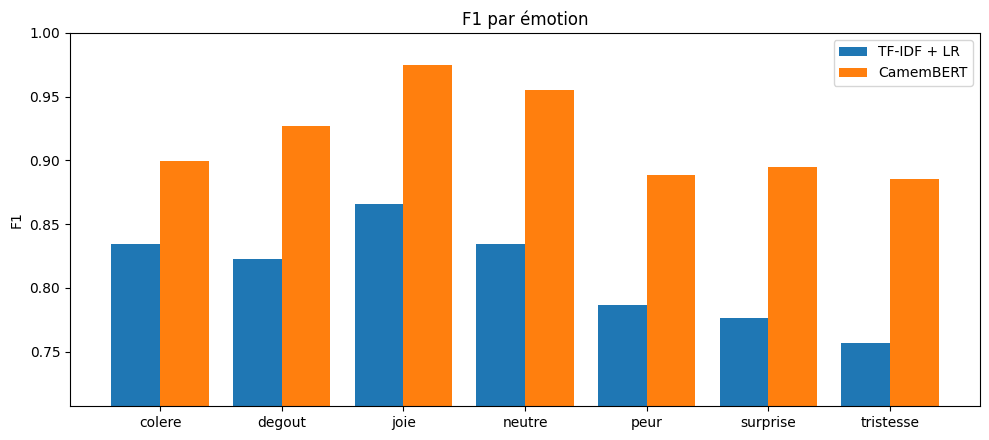

In [61]:
x = np.arange(len(classes))
plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.2, f1_lr, 0.4, label="TF-IDF + LR")
plt.bar(x + 0.2, f1_cb, 0.4, label="CamemBERT")
plt.xticks(x, classes)
plt.ylabel("F1")
plt.ylim(min(f1_lr.min(), f1_cb.min()) - 0.05, 1.0)
plt.title("F1 par émotion")
plt.legend()
plt.tight_layout()
plt.savefig("f1_par_classe.png", dpi=150)
plt.show()

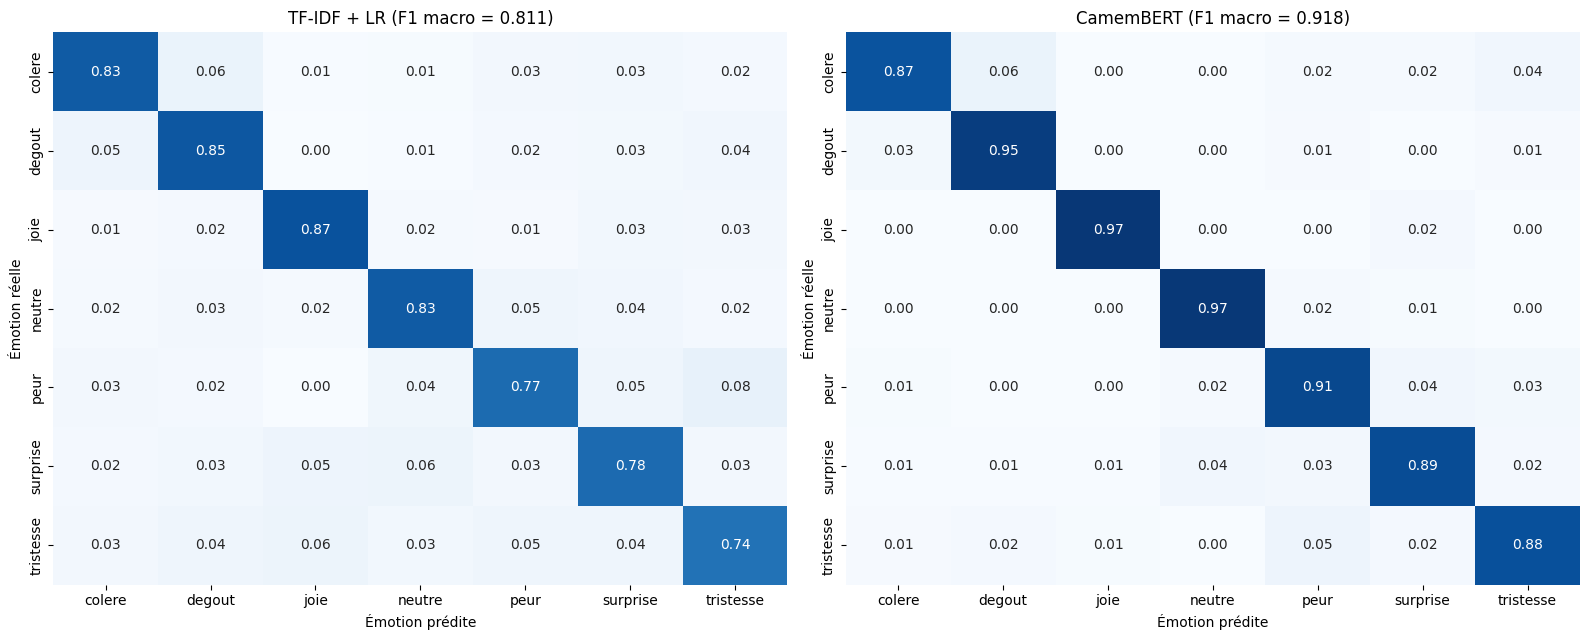

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, pred, nom in zip(axes, [pred_lr, pred_cb], ["TF-IDF + LR", "CamemBERT"]):
    cm = confusion_matrix(y_test, pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(f"{nom} (F1 macro = {f1_score(y_test, pred, average='macro'):.3f})")
    ax.set_xlabel("Émotion prédite")
    ax.set_ylabel("Émotion réelle")
plt.tight_layout()
plt.savefig("confusion.png", dpi=150)
plt.show()

In [65]:
def top_confusions(y, pred, n=8):
    cm = confusion_matrix(y, pred)
    np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:n], cm.shape))[0]
    return pd.DataFrame([
        {"Réel": classes[i], "Prédit": classes[j], "Nb erreurs": cm[i, j]}
        for i, j in idx
    ])

print("TF-IDF + LR\n", top_confusions(y_test, pred_lr), "\n")
print("CamemBERT\n", top_confusions(y_test, pred_cb))

TF-IDF + LR
         Réel     Prédit  Nb erreurs
0       peur  tristesse          24
1     colere     degout          19
2   surprise     neutre          17
3  tristesse       joie          17
4   surprise       joie          16
5     degout     colere          16
6       peur   surprise          15
7  tristesse       peur          15 

CamemBERT
         Réel     Prédit  Nb erreurs
0     colere     degout          19
1  tristesse       peur          16
2       peur   surprise          11
3     colere  tristesse          11
4   surprise     neutre          11
5   surprise       peur           9
6     degout     colere           8
7       peur  tristesse           8


In [67]:
ok_lr = (pred_lr == y_test)
ok_cb = (pred_cb == y_test)

b = int((ok_lr & ~ok_cb).sum())   # LR juste, CamemBERT faux
c = int((~ok_lr & ok_cb).sum())   # LR faux, CamemBERT juste
print(f"LR seul correct : {b} | CamemBERT seul correct : {c}")

p = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
print(f"p-value (McNemar exact) : {p:.4f}")

LR seul correct : 71 | CamemBERT seul correct : 295
p-value (McNemar exact) : 0.0000


In [69]:
classes = list(encoder.classes_)
err = test[[TEXT, LABEL]].copy().reset_index(drop=True)
err["pred_lr"] = [classes[i] for i in pred_lr]
err["pred_cb"] = [classes[i] for i in pred_cb]
err["lr_ok"] = err["pred_lr"] == err[LABEL]
err["cb_ok"] = err["pred_cb"] == err[LABEL]
err["len"] = err[TEXT].str.split().str.len()

In [70]:
# Confiance de CamemBERT (probabilité de sa prédiction)
probs = softmax(out.predictions, axis=1)
err["conf_cb"] = probs.max(axis=1)

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 250)

In [71]:
groupes = {
    "Les deux corrects": err[err.lr_ok & err.cb_ok],
    "Les deux faux": err[~err.lr_ok & ~err.cb_ok],
    "LR faux, CamemBERT juste": err[~err.lr_ok & err.cb_ok],
    "LR juste, CamemBERT faux": err[err.lr_ok & ~err.cb_ok],
}
for nom, g in groupes.items():
    print(f"{nom:28s}: {len(g):5d}  ({len(g)/len(err):.1%})")

Les deux corrects           :  1633  (77.8%)
Les deux faux               :   101  (4.8%)
LR faux, CamemBERT juste    :   295  (14.0%)
LR juste, CamemBERT faux    :    71  (3.4%)


In [72]:
both = groupes["Les deux faux"]
print(both.sample(min(25, len(both)), random_state=0)[[TEXT, LABEL, "pred_lr", "pred_cb"]].to_string())

                                                                                                     text      label    pred_lr    pred_cb
591                     Ce film est un gâchis monumental, un budget de blockbuster pour un résultat de Z.     degout     colere     colere
1796                                                                              Il a neigé des cendres.   surprise       peur       peur
64                                                 Le silence dans la vieille maison était assourdissant.  tristesse       peur       peur
1170                                           La nouvelle de cette attaque terroriste m'a glacé le sang.  tristesse       peur       peur
1600                                  J'ai l'impression que mes pieds ne touchent plus le sol, je flotte.       joie  tristesse       peur
1925                                    Des ombres dansaient sur les murs au gré du feu dans la cheminée.     neutre       peur       joie
344   Le plat surgelé était

In [73]:
print("=== LR FAUX, CamemBERT JUSTE ===")
g = groupes["LR faux, CamemBERT juste"]
print(g.sample(min(12, len(g)), random_state=1)[[TEXT, LABEL, "pred_lr"]].to_string())

=== LR FAUX, CamemBERT JUSTE ===
                                                                                               text      label    pred_lr
1699            Une cascade de sensations positives déferle en moi, emportant tout sur son passage.       joie     colere
1333                              Putain, j'ai effacé la sauvegarde du cloud au lieu de la locale !   surprise     neutre
1116                                        Le tri sélectif est devenu obligatoire dans la commune.     neutre       peur
1625                              Ils ont trouvé une chambre secrète au cœur de la Grande Pyramide.   surprise  tristesse
2094                                                  Cet aspirateur a une puissance de 1200 watts.     neutre   surprise
1414                                               Attention à la fermeture automatique des portes.     neutre  tristesse
1947  Une vieille cabine téléphonique hors service se dressait, solitaire, sur le bord de la route.  tristesse   

In [74]:

print("\n=== LR JUSTE, CamemBERT FAUX ===")
g = groupes["LR juste, CamemBERT faux"]
print(g.sample(min(12, len(g)), random_state=1)[[TEXT, LABEL, "pred_cb"]].to_string())


=== LR JUSTE, CamemBERT FAUX ===
                                                                                  text      label    pred_cb
1960                            Nous avons vu notre photo dans le journal de ce matin.   surprise     neutre
891                                                     Je suis scié, tout simplement.   surprise  tristesse
2050                 J'ai l'impression d'être transparent, personne ne semble me voir.  tristesse       peur
1623                                  Nous regardons, impuissants, la montée des eaux.  tristesse       peur
906       La vieille horloge grand-père s'est remise à sonner après 50 ans de silence.   surprise  tristesse
1843  Mon podcast préféré vient de sortir un épisode surprise, ma journée est refaite.       joie   surprise
1462                                     Je serre la mâchoire à m'en broyer les dents.     colere       peur
1073                                               J'ai juste une boule dans la gorge.  triste

In [75]:
err["tranche"] = pd.qcut(err["len"], 4, duplicates="drop")
print(err.groupby("tranche", observed=True).agg(
    n=("len", "size"),
    erreur_LR=("lr_ok", lambda s: 1 - s.mean()),
    erreur_CB=("cb_ok", lambda s: 1 - s.mean()),
).round(3))

                n  erreur_LR  erreur_CB
tranche                                
(1.999, 9.0]  619      0.220      0.099
(9.0, 11.0]   498      0.203      0.082
(11.0, 13.0]  462      0.180      0.093
(13.0, 23.0]  521      0.146      0.052


In [77]:
print("Confiance moyenne si correct :", err[err.cb_ok]["conf_cb"].mean().round(3))
print("Confiance moyenne si faux    :", err[~err.cb_ok]["conf_cb"].mean().round(3))

sur = err[~err.cb_ok].sort_values("conf_cb", ascending=False).head(15)
print(sur[[TEXT, LABEL, "pred_cb", "conf_cb"]].round(3).to_string())

Confiance moyenne si correct : 0.954
Confiance moyenne si faux    : 0.834
                                                                                         text      label    pred_cb  conf_cb
190                                                                   Je suis scié sur place.   surprise     neutre    0.974
745                                 Le comité d'éthique a approuvé notre projet de recherche.   surprise     neutre    0.973
1873                                      L'odeur de terre fraîche vient de sous le plancher.       peur     neutre    0.973
1299                           Je suis une maison aux volets clos au milieu d'un été radieux.  tristesse       joie    0.971
1736                                                         Le bâtiment n'a pas de fenêtres.       peur     neutre    0.971
1769                         L'enregistrement audio est d'une clarté parfaite malgré son âge.   surprise     neutre    0.970
2080                                   Le système d

In [78]:
mes_phrases = [
    "Franchement je m'attendais pas à ça, bravo !",
    "Je ne suis pas du tout content de ce service.",
    "Il y a un bruit bizarre dans la cave depuis hier soir.",
    "Le train partira à 14h32 du quai 5.",
    "Mdr trop bien ce film, j'ai adoré",
    "Tu m'as menti pendant des mois et tu oses me regarder en face ?",
    "Encore une journée à regarder la pluie tomber.",
    "Ce plat sent le renfermé et la graisse froide.",
]
tok_in = tok(mes_phrases, return_tensors="pt", padding=True, truncation=True, max_length=64).to(model.device)
model.eval()
with torch.no_grad():
    lg = model(**tok_in).logits
p_cb = [classes[i] for i in lg.argmax(-1).cpu().numpy()]
p_lr = [classes[i] for i in gs.predict(mes_phrases)]

print(pd.DataFrame({"phrase": mes_phrases, "TF-IDF+LR": p_lr, "CamemBERT": p_cb}).to_string())

                                                            phrase TF-IDF+LR  CamemBERT
0                     Franchement je m'attendais pas à ça, bravo !  surprise   surprise
1                    Je ne suis pas du tout content de ce service.  surprise  tristesse
2           Il y a un bruit bizarre dans la cave depuis hier soir.      peur       peur
3                              Le train partira à 14h32 du quai 5.    neutre     neutre
4                                Mdr trop bien ce film, j'ai adoré      peur       joie
5  Tu m'as menti pendant des mois et tu oses me regarder en face ?  surprise     colere
6                   Encore une journée à regarder la pluie tomber.      joie  tristesse
7                   Ce plat sent le renfermé et la graisse froide.    degout     degout


In [79]:
err.to_csv("/content/drive/MyDrive/EmoFR/analyse_erreurs.csv", index=False)

In [82]:
notebook_login()

In [83]:
REPO = "AbdelkarimAouad/camembert-emofr"

model.push_to_hub(REPO, private=True)
tok.push_to_hub(REPO, private=True)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...3ry2u58/model.safetensors:   0%|          |  552kB /  443MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/AbdelkarimAouad/camembert-emofr/commit/5b2d6c35017bcd52c333926a810527e7b93215bd', commit_message='Upload tokenizer', commit_description='', oid='5b2d6c35017bcd52c333926a810527e7b93215bd', pr_url=None, repo_url=RepoUrl('https://huggingface.co/AbdelkarimAouad/camembert-emofr', endpoint='https://huggingface.co', repo_type='model', repo_id='AbdelkarimAouad/camembert-emofr'), pr_revision=None, pr_num=None)

In [87]:
clf = pipeline("text-classification", model=REPO, top_k=None)
print(clf("Je ne suis pas du tout content de ce service."))

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/431 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

[[{'label': 'tristesse', 'score': 0.9578719735145569}, {'label': 'colere', 'score': 0.011851404793560505}, {'label': 'joie', 'score': 0.007083606440573931}, {'label': 'degout', 'score': 0.006570001598447561}, {'label': 'peur', 'score': 0.006534234154969454}, {'label': 'surprise', 'score': 0.005599266849458218}, {'label': 'neutre', 'score': 0.004489506594836712}]]
